# Experiências de comunicação com e sem SA

In [ ]:
from pathlib import Path
import sys
root=Path.cwd().resolve()
while not (root/'requirements.txt').exists() and root!=root.parent: root=root.parent
sys.path.insert(0,str(root))

# Comunicação e PR-AUC — Softlabels

**Comparação emparelhada com/sem SA dentro de cada abordagem.** Mesmos IDs, cinco seeds (2031–2035), três rondas e dez épocas locais. 22 clientes, pesos de fit: 72,73% Icentia e 27,27% PhysioNet. Sem desistências nesta comparação. SA: soma única, 24 bits, limiar 12. FedAvg usa CNN1D comum; Soft Labels usa professores AE+CNN/MobileNetV2 e aluno CNN1D. A diferença entre abordagens inclui arquitetura/objetivo e custo de treino distintos; as épocas iguais não igualam FLOPs.

{'status': 'complete', 'validated_runs': 20, 'signature': '590f95d2e0ae0804092eeab9326543fffa70e3b18e6d11584e39f0b18bdacb98'}

**20/20 execuções concluídas e validadas.** Barras parciais só incluem execuções completas; `n` indica seeds disponíveis.

PR-AUC local: professor no próprio holdout nas Soft Labels; rede local após treino, antes da agregação, em FedAvg. PR-AUC global: o modelo global avaliado nos mesmos holdouts. Média ponderada dos AP individuais, não uma curva conjunta. O modelo FedAvg entregue ao cliente após agregação corresponde à barra global. Dev é secundário e está nas tabelas por cliente; test não é usado. AP indefinida num holdout com uma só classe é excluída, com cobertura explícita nas tabelas.

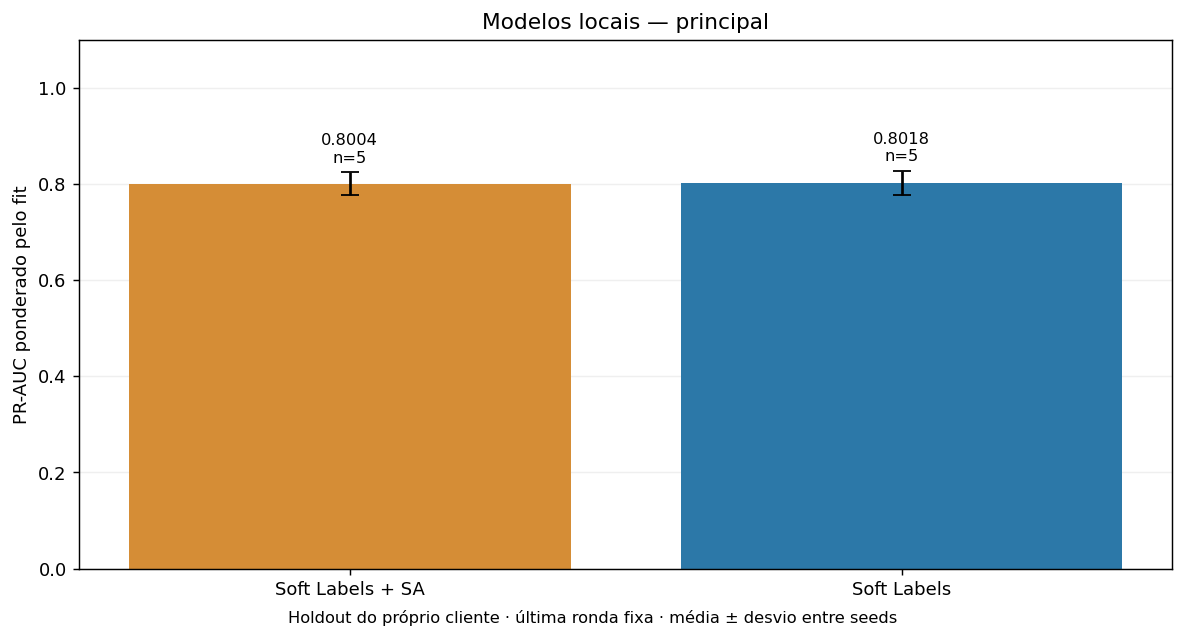

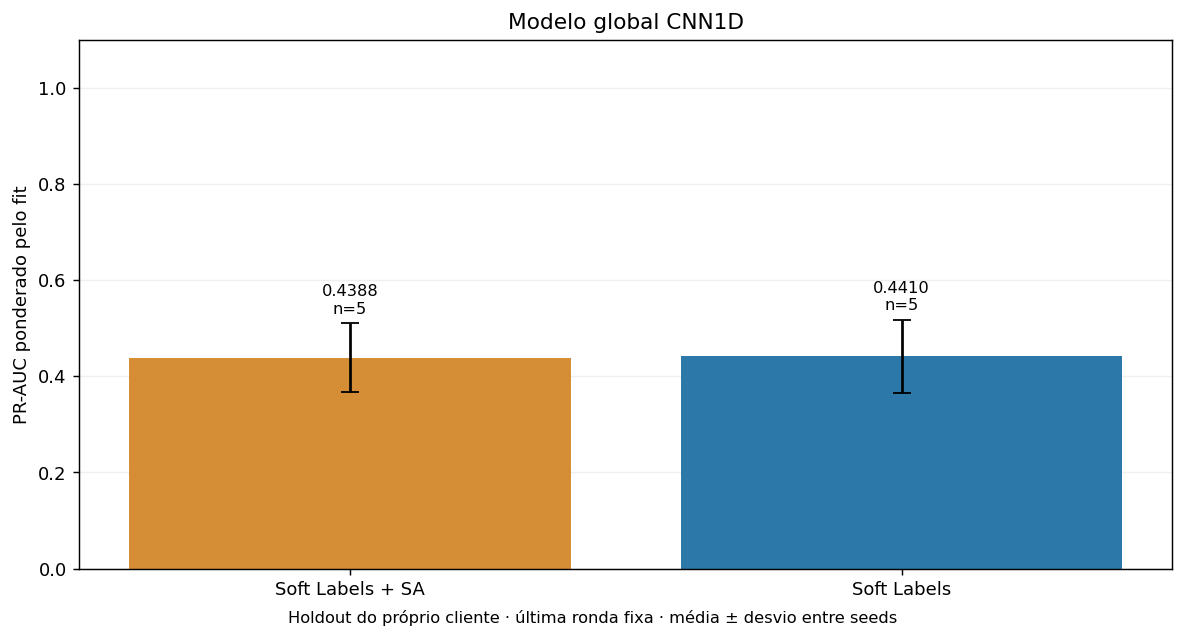

algorithm,condition,seed,role,pr_auc_ap,roc_auc,recall,far,f1,valid_ap_clients,total_clients,ap_fit_coverage
Softlabels,SA,2031,global,0.440535,0.511685,0.300699,0.305646,0.222558,22,22,1.0
Softlabels,SA,2031,local,0.800708,0.856585,0.630432,0.090920,0.643605,22,22,1.0
Softlabels,SA,2032,global,0.505314,0.564610,0.937063,0.915945,0.450422,22,22,1.0
Softlabels,SA,2032,local,0.777926,0.821223,0.724026,0.177432,0.699396,22,22,1.0
Softlabels,SA,2033,global,0.318601,0.324350,0.068619,0.185334,0.094192,22,22,1.0
Softlabels,SA,2033,local,0.839294,0.868800,0.741196,0.159684,0.709317,22,22,1.0
Softlabels,SA,2034,global,0.477979,0.568581,1.000000,0.985508,0.460739,22,22,1.0
Softlabels,SA,2034,local,0.785478,0.834052,0.600462,0.146650,0.605631,22,22,1.0
Softlabels,SA,2035,global,0.451439,0.530458,1.000000,0.997067,0.457817,22,22,1.0
Softlabels,SA,2035,local,0.798561,0.853729,0.708666,0.162575,0.678885,22,22,1.0


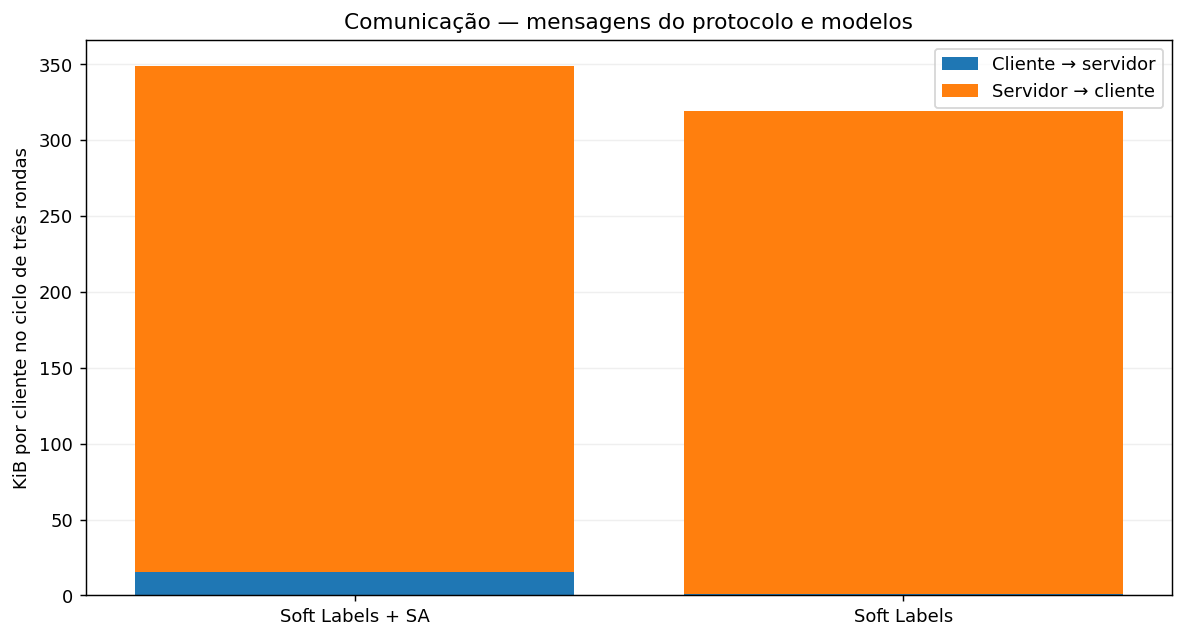

algorithm,condition,seed,upload_bytes,download_bytes,total_bytes,aggregation_seconds,local_compute_seconds
Softlabels,SA,2031,350064,7509920,7859984,6.005670,1666.745800
Softlabels,SA,2032,350064,7509920,7859984,4.020914,1164.760554
Softlabels,SA,2033,350064,7509920,7859984,4.009358,1157.875132
Softlabels,SA,2034,350064,7509920,7859984,4.932616,1454.197553
Softlabels,SA,2035,350064,7509920,7859984,5.405786,2259.877847
Softlabels,plain,2031,17160,7182560,7199720,0.000058,1622.775829
Softlabels,plain,2032,17160,7182560,7199720,0.000054,1592.655218
Softlabels,plain,2033,17160,7182560,7199720,0.000045,1243.701335
Softlabels,plain,2034,17160,7182560,7199720,0.000050,1185.214595
Softlabels,plain,2035,17160,7182560,7199720,0.000059,1870.979222


condition,algorithm,seed,role,SA,plain,SA_minus_plain
,Softlabels,2031,global,0.440535,0.452283,-0.011748
,Softlabels,2031,local,0.800708,0.788336,0.012372
,Softlabels,2032,global,0.505314,0.504633,0.000682
,Softlabels,2032,local,0.777926,0.788149,-0.010222
,Softlabels,2033,global,0.318601,0.309112,0.009489
,Softlabels,2033,local,0.839294,0.844688,-0.005394
,Softlabels,2034,global,0.477979,0.485029,-0.007050
,Softlabels,2034,local,0.785478,0.782420,0.003057
,Softlabels,2035,global,0.451439,0.453975,-0.002535
,Softlabels,2035,local,0.798561,0.805574,-0.007012


Comunicação: soma dos payloads de upload e download; inclui chaves, partilhas e desmascaramento da SA, distribuição inicial e três distribuições globais (uma após cada ronda). Contagem por mensagem lógica, sem cabeçalhos TCP/TLS nem retransmissões. Âncoras sintéticas geradas localmente; preparação inicial dos dados não contabilizada. Tempos medidos localmente, sem latência de rede. FedAvg: parâmetros com sinal codificados por transformação afim com limite público ±256, sem clipping silencioso; buffers inteiros são arredondados. Soft Labels: probabilidades ponderadas em [0,1]. Os 24 bits não representam o mesmo erro absoluto nos dois espaços. SA não oferece LDP nem esta simulação constitui uma validação de segurança para produção.

In [1]:
from support.sa_communication_report import render
render('Softlabels')